In [8]:
#Simple Pendulum: d^2 theta / dt^2 + g / L * sin theta = 0

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt1

#set length of the pendulum
L = 1

def f(theta, w):
    return w, - 9.8 / L * np.sin(theta)

PLOT FOR X(T) and V(T):


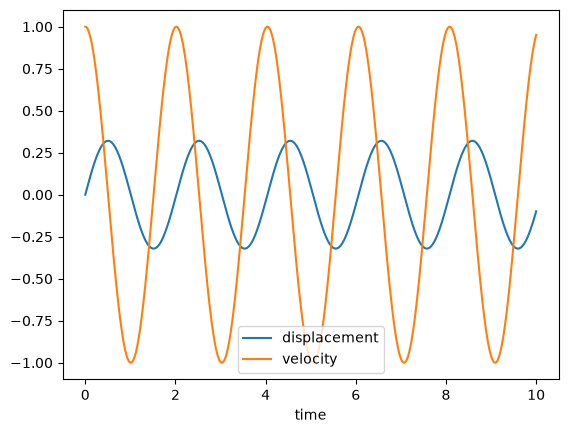

PLOT FOR X VS V:


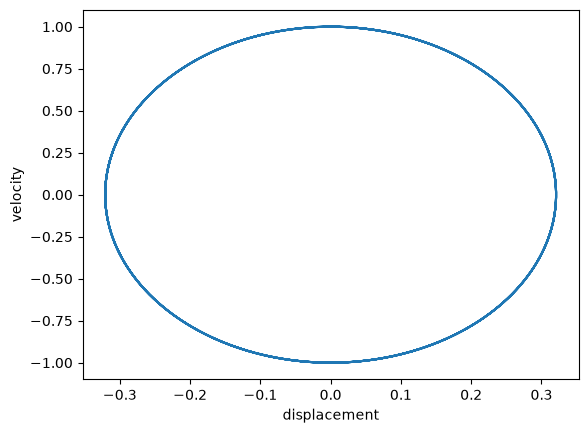

In [12]:
#using rk4

#using rk4 method

t0 = 0
tmax = 10

#set time-step
h = 0.01

#set initial conditions
theta0 = 0
w0 = 1

time = [t0]
displacement = [theta0]
velocity = [w0]

while t0 < tmax - 1e-12:
    k1theta, k1w = f(theta0, w0)
    k2theta, k2w = f(theta0 + h/2*k1theta, w0 + h/2*k1w)
    k3theta, k3w = f(theta0 + h/2*k2theta, w0 + h/2*k2w)
    k4theta, k4w = f(theta0 + h*k3theta, w0 + h*k3w)    
    w0 = w0 + h * (k1w + 2 * k2w + 2 * k3w + k4w) / 6  
    theta0 = theta0 + h * (k1theta + 2 * k2theta + 2 * k3theta + k4theta) / 6

    
    t0 = t0 + h

    time.append(t0)
    displacement.append(theta0)
    velocity.append(w0)

print("PLOT FOR X(T) and V(T):")
plt.plot(time, displacement)
plt.plot(time, velocity)
plt.xlabel("time")
plt.legend(["displacement", "velocity"])
plt.show()

print("PLOT FOR X VS V:")
plt1.plot(displacement, velocity)
plt1.xlabel("displacement")
plt1.ylabel("velocity")
plt1.show()

In [38]:
#animation
from matplotlib.animation import FuncAnimation
import matplotlib.pyplot as plt
from IPython.display import HTML, display

x = L * np.sin(displacement)
y = - L * np.cos(displacement)

fig, ax = plt.subplots(figsize=(6, 6))

ax.set_xlim(-1.3 * L, 1.3 * L)
ax.set_ylim(-1.3 * L, 0.3 * L)

#fixed pivot
ax.plot(0, 0, "ko", markersize=6)

#pendulum thread
thread, = ax.plot([], [], "k-", linewidth=2)

#pendulum bob
bob, = ax.plot([], [], "o", color="red", markersize=14)

#trace of the bob's path
trace, = ax.plot([], [], "b--", alpha=0.5, linewidth=1)


def update(i):
    thread.set_data([0, x[i]], [0, y[i]])
    bob.set_data([x[i]], [y[i]])
    trace.set_data(x[:i+1], y[:i+1])

    return thread, bob, trace

ani = FuncAnimation(fig, update, frames=len(time), interval=20, blit=True, repeat=True)

plt.close(fig)
display(HTML(ani.to_jshtml()))